In [29]:
from langgraph.graph import StateGraph ,START,END
from typing import TypedDict

In [30]:
class BMIInput(TypedDict):
    height:float
    weight:float
    label:str
    bmi:float

In [31]:
def calculate_bmi(state:BMIInput)->BMIInput:
    height=state['height']
    weight=state['weight']
    bmi=weight/(height**2)
    state['bmi']=round(bmi,2)
    return state

In [32]:
def add_label(state:BMIInput)->BMIInput:
    bmi=state['bmi']
    label="fit"
    if(bmi<18.5):
        label="underWeight"
    elif(bmi>=18.5 and bmi<=24.9):
        label="fit"
    elif(bmi>=25 and bmi<=29.9):
        label="overWeight"
    else:
        label="obese"
    state['label']=label
    return state

In [33]:
##create graph
graph=StateGraph(BMIInput)

##create Nodes
graph.add_node("calculate_bmi",calculate_bmi)
graph.add_node("add_label",add_label)

##create edges
graph.add_edge(START,"calculate_bmi")
graph.add_edge("calculate_bmi","add_label")
graph.add_edge("add_label",END)

##compile the graph
workflow=graph.compile()

##execute the graph
initial_state={'height':1.90,'weight':52}
final_state=workflow.invoke(initial_state)
print(final_state)


{'height': 1.9, 'weight': 52, 'label': 'underWeight', 'bmi': 14.4}


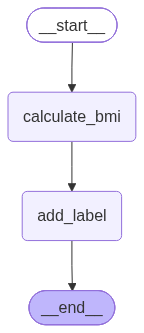

In [36]:
from IPython.display import Image
Image(workflow.get_graph().draw_mermaid_png())